# Stage B · names, contracts, and a reusable module

**Assumed background:** functions and DataFrames are familiar. The goal is to choose useful responsibilities and explicit dependencies, not to practice function syntax. Compare with Stage A's reference result.

The seeded synthetic CSV, inclusive 0.2–2.0 s rule, error retention, participant weighting, and summary definitions remain unchanged. `helpers.py` contains stable computation and a separate plotting function. Stage C will share reviewed configuration between notebook and script.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
project_root = next((p for p in (cwd, cwd.parent) if (p / "data/raw/trials.csv").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Start Jupyter from motion-perception and open notebooks/; raw_trials CSV not found")
print("Python:", sys.executable)
print("Project:", project_root.name)

Python: workshop .venv (Python 3.11)
Project: motion-perception


## Import the extracted module

The helper file sits beside this notebook. This intermediate stage has one explicit directory adjustment only if the kernel was launched at project root. Stage C removes that import-location dependency through package installation. Restart after editing helpers to ensure the kernel uses the saved implementation.

In [2]:
import os
if Path.cwd().resolve() == project_root:
    os.chdir(project_root / "notebooks")
from helpers import clean_trials, summarize, plot_accuracy

## Use explicit input and one filter

Stage B assumes the supplied data schema. Stage C will add full validation. The raw table stays untouched.

In [3]:
analysis_settings = {"min_rt_s": 0.2, "max_rt_s": 2.0}
raw_trials = pd.read_csv(project_root / "data/raw/trials.csv")
filtered_trials = clean_trials(raw_trials, **analysis_settings)
condition_metrics = summarize(filtered_trials)

In [4]:
condition_metrics = condition_metrics.sort_values("condition").reset_index(drop=True)
print(condition_metrics.to_string(index=False))
print("SUMMARY_JSON=" + condition_metrics.to_json(orient="records", double_precision=15))
print("RETAINED=" + str(len(filtered_trials)))

condition  accuracy      sem  median_rt  n_participants
    clear  0.808111 0.009015   0.786242              24
    noisy  0.713384 0.009482   0.970044              24
SUMMARY_JSON=[{"condition":"clear","accuracy":0.808110967170552,"sem":0.009014669982837,"median_rt":0.786241666666667,"n_participants":24},{"condition":"noisy","accuracy":0.713383545700543,"sem":0.009481544947741,"median_rt":0.970043541666667,"n_participants":24}]
RETAINED=3761


## Keep drawing separate from calculation

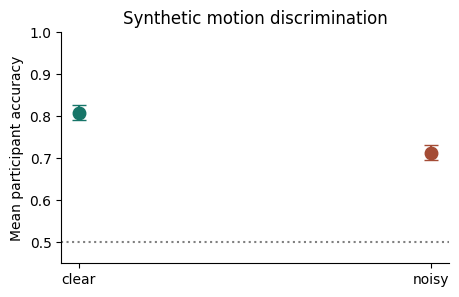

In [5]:
figure = plot_accuracy(condition_metrics)
plt.show()
plt.close(figure)

## Exercise · make the policy reusable

Explain which dependencies belong in `clean_trials` and which belong in the notebook. Why should the helper not open a config file itself? In a scratch cell, compare a 0.6 s minimum RT using a new `sensitivity_trials` name without modifying `filtered_trials` or the baseline summary.

<details><summary>Solution and tradeoff</summary>The helper needs a trial table and explicit bounds. File discovery and parameter selection belong at the entry point. The notebook dictionary is a useful first step; it becomes a shared TOML file in Stage C once the script needs the same settings. Preserve the baseline and document the motivation for any alternative policy.</details>